# Macroeconomics — Hong Kong Cash Handouts
**CORE Doing Economics · Empirical Project 12**  
Group 1: de los Reyes, Demirel, Yeranyan, Zhao

## Introduction and research question
Hong Kong announced Scheme $6,000 in March 2011, after changing its original proposal to contribute to Mandatory Provident Fund accounts. Registration began in August 2011. The cash scheme paid eligible adult permanent residents; the CORE exercise simplifies this into one payment per model household in 2012.

**Research question:** Did the 2011 cash handout reduce income inequality, and was it followed by an improvement in government popularity?

### Contents
- Setup and data sources
- CORE Part 12.1 — Inequality: Q1 real incomes; Q2 household model and Lorenz curves; Q3 Gini; Q4 alternative transfers and taxation
- CORE Part 12.2 — Government popularity: Q1 supporters/opponents; Q2 survey methodology; Q3 public opinion trends; Q4 the 2018 comparison; Q5 policy recommendation
- Appendix — optional inflation extension
- Final validation and references

[CORE Project 12: Working in Python](https://books.core-econ.org/doing-economics/book/text/12-06.html)

## Setup — dependencies and reproducibility
Run from the repository root with the four original Excel files in `data/`. Install dependencies once, if necessary: `python -m pip install pandas openpyxl matplotlib numpy lets-plot ipykernel`. The original CORE lets-plot visualizations are used when available; Matplotlib provides equivalent charts otherwise. Restart the kernel and run all cells in order.

The four source spreadsheets are available in the group repository at https://github.com/sdanieldlr/macro_final/tree/main/data. This notebook uses the files by name; the saved outputs can be regenerated from the original spreadsheets.

**Data sources:** the CORE household-income workbook contains nominal and real household-income thresholds and consumer price changes; the three HKU POP/PORI workbooks contain aggregate opinion surveys. All four original files belong in `data/`. The saved outputs in this downloadable version were checked using the original government-satisfaction workbook and reconstructed validation workbooks containing the relevant values extracted from the other three original source spreadsheets. Re-run with the four original GitHub files before submission.

In [85]:
# Imports (install packages once using the command above, not during each run).
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from IPython.display import display
try:
    from lets_plot import *
    from lets_plot.mapping import as_discrete
    LetsPlot.setup_html(no_js=True)
    USE_LETS_PLOT = True
except ImportError:
    USE_LETS_PLOT = False
Path("outputs").mkdir(exist_ok=True)
print("Plotting library:", "lets-plot" if USE_LETS_PLOT else "Matplotlib")

Plotting library: Matplotlib


## CORE Part 12.1 — Inequality
### Question 1 — Monthly real household income (2009–2016)

In [86]:
# saving the file
income = pd.read_excel(
    
    Path("data/doing-economics-project-12-datafile.xlsx"), # importing the data
    skiprows=12                                            # skipping the nominal table (using the real table)
    
    )

# cleaning the file (removing NaNs and renaming)
income = income.dropna(axis=0).rename(columns={"Unnamed: 0" : "Percentile"})
             # .dropna(axis=0) - specifies that we want to drop the rows with missing values
             # .rename - renaming the columns named "Unnamed: 0" with "Percentile"

In [87]:
# turning the file into a long format
income_melted = pd.melt(
    # pd.melt() - reshaping the data from a wide format (one column per year) into a long format (single column for all years)
    #           - required because the next structure "lets-plot" expects long-format data

    income,                       # the dataset being used
    id_vars="Percentile",         # keeps percentile as a fixed identifier column
    value_vars=range(2009, 2017), # selects the columns for years 2009 - 2016 (range stops one before 2017)
    var_name="Year"               # chooses the name for the new column

)

In [88]:
income.head(2) # wide format

,Percentile,2009,2010,2011,2012,2013,2014,2015,2016
0,85th,43300.0,43945.3125,44515.669516,44544.177789,45270.209450,45162.212854,47659.574562,47085.549738
1,75th,31000.0,31250.0000,32273.860399,32517.249786,34166.195812,33298.950420,34791.489430,34906.914962


In [89]:
income_melted.head(2) # long format

,Percentile,Year,value
0,85th,2009,43300.0
1,75th,2009,31000.0


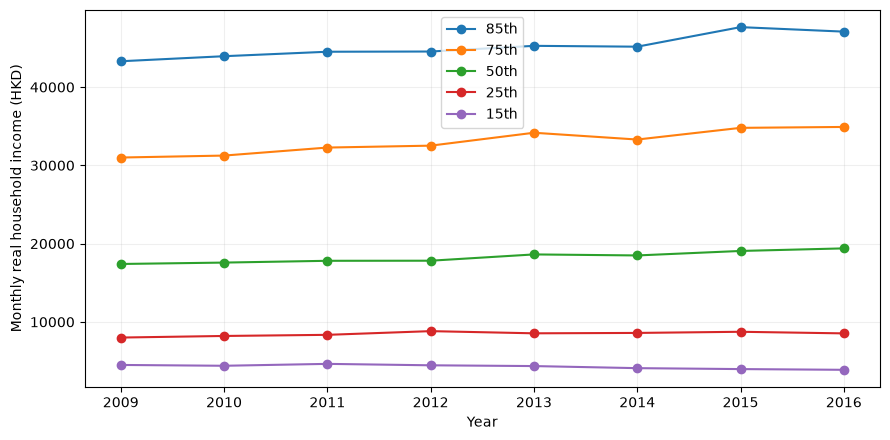

In [90]:
if USE_LETS_PLOT:
    # plotting income_melted
    # (putting the whole ggplot command inside parenthesis allows python to read it as a single plot)
    display(
        ggplot(
        
            income_melted, # dataset being used
        
            aes( # aesthetics
                x=as_discrete("Year"), # plots year along the x-axis (as discrete/categorical) 
                y="value",             # plots "value" which is the income along the y-axis
                color="Percentile"     # splits the data by the "Percentile" column (uses color)
                )
            
                )
    
        + geom_line(size=1) # thickness of line
    
        + labs(y="Monthly real household income (HKD)") # labels the y-axis
    
        + scale_x_continuous(format="d")                # ensures x-axis (year) is displayed as a whole number

    )
else:
    fig, ax = plt.subplots(figsize=(9,4.5))
    for name, group in income_melted.groupby("Percentile", sort=False):
        ax.plot(group["Year"], group["value"], marker="o", label=name)
    ax.set(xlabel="Year", ylabel="Monthly real household income (HKD)")
    ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show()

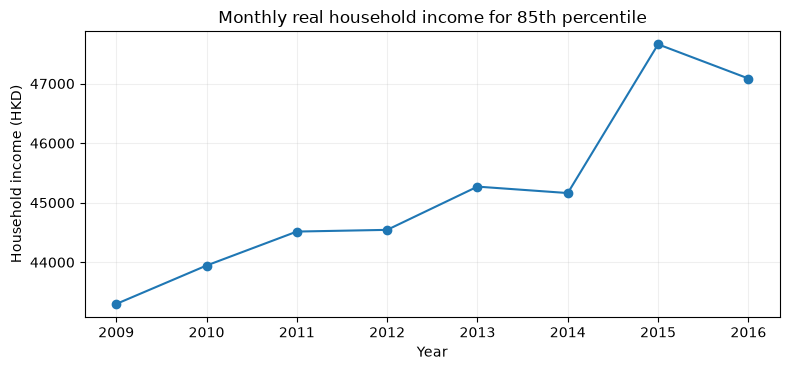

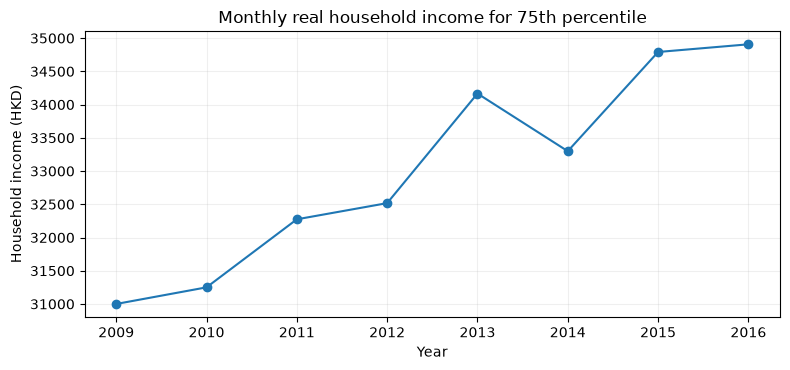

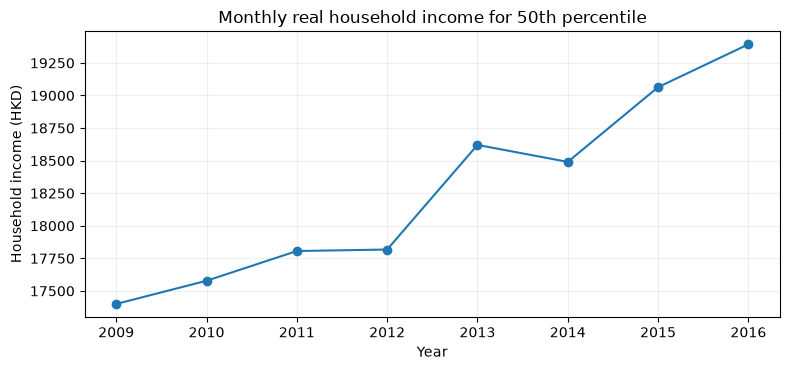

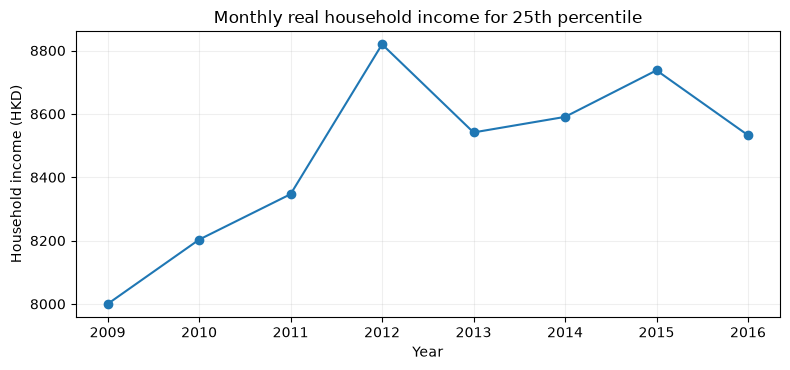

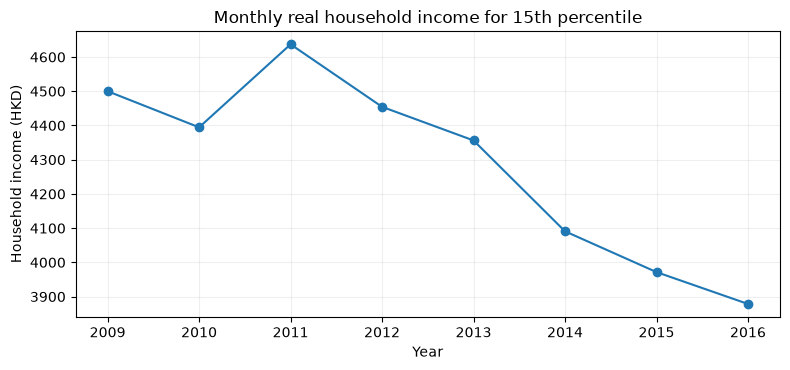

In [91]:
if USE_LETS_PLOT:
    percentiles = income["Percentile"].tolist() # lists the percentiles on the income dataset (same as income_melted)

    for perct_to_use in percentiles: # for each percentile (perct_to_use) in percentiles

        p = (
        
            ggplot(
            
                income_melted.loc[income_melted["Percentile"] == perct_to_use, :], # only the rows with the desired percentile
                           # .loc[rows,columns] - columns is kept empty because we're using all         
            
                aes(x=as_discrete("Year"), y="value"),                             # selecting x-axis (categorical) and y-axis
        
            )
            + geom_line(size=1)  # line thickness
            + geom_point(size=3) # points for each year
            + labs(
                title=f"Monthly real household income for {perct_to_use} percentile", # adds a title
                y="Household income (HKD)",                                           # y-axis label
            )
            + scale_x_continuous(format="d") # whole number label
        )

        display(p) # displaying the created plot
else:
    percentiles = income["Percentile"].tolist()
    for perct_to_use in percentiles:
        group = income_melted.loc[income_melted["Percentile"] == perct_to_use]
        fig, ax = plt.subplots(figsize=(8,3.8))
        ax.plot(group["Year"], group["value"], marker="o")
        ax.set(title=f"Monthly real household income for {perct_to_use} percentile", xlabel="Year", ylabel="Household income (HKD)")
        ax.grid(alpha=.2); fig.tight_layout(); plt.show()

#### Income summary: absolute and percentage change, 2009–2016

In [92]:
income_summary = income.set_index("Percentile")[[2009, 2016]]
income_summary["Change (HKD)"] = income_summary[2016] - income_summary[2009]       # absolute change per month
income_summary["Change (%)"] = 100 * (income_summary[2016] / income_summary[2009] - 1)  # percentage change

Path("outputs").mkdir(exist_ok=True)                        # folder for exported files
income_summary.round(1).to_csv("outputs/income_summary.csv")  # export the summary
income_summary.round(1)

,2009,2016,Change (HKD),Change (%)
Percentile,,,,
85th,43300.0,47085.5,3785.5,8.7
75th,31000.0,34906.9,3906.9,12.6
50th,17400.0,19392.7,1992.7,11.5
25th,8000.0,8532.8,532.8,6.7
15th,4500.0,3878.5,-621.5,-13.8


In [93]:
if USE_LETS_PLOT:
    # export the five percentile charts as image files
    for perct_to_use in percentiles:
        p = (
            ggplot(income_melted.loc[income_melted["Percentile"] == perct_to_use, :],
                   aes(x=as_discrete("Year"), y="value"))
            + geom_line(size=1) + geom_point(size=3)
            + labs(title=f"Monthly real household income for {perct_to_use} percentile", y="Household income (HKD)")
            + scale_x_continuous(format="d")
        )
        ggsave(p, f"income_{perct_to_use}.svg", path="outputs")
else:
    for perct_to_use in percentiles:
        group = income_melted.loc[income_melted["Percentile"] == perct_to_use]
        fig, ax = plt.subplots(figsize=(8,3.8))
        ax.plot(group["Year"], group["value"], marker="o")
        ax.set(title=f"Monthly real household income for {perct_to_use} percentile", xlabel="Year", ylabel="Household income (HKD)")
        ax.grid(alpha=.2); fig.tight_layout()
        fig.savefig(Path("outputs") / f"income_{perct_to_use}.svg"); plt.close(fig)

**Interpretation (CORE 12.1 Q1):** From 2009 to 2016 the 15th-percentile real income falls by about 13.8%, while the four higher income thresholds rise. These are pre-intervention incomes; the cash payment is not included. The data describe percentile thresholds, not the same households followed through time.

### Question 2 — Constructing 100 households and plotting Lorenz curves (2011–2012)
We approximate the household distribution using six income bands. Each household is assigned its band’s lower income threshold; the bottom 15 are assigned zero. Annual incomes equal monthly income × 12. The 2012 transfer scenario adds HK$6,000 once per model household. Lorenz shares use group income (income per household × household count), not equally weighted bands.

In [94]:
cols_of_interest = ["Percentile", 2011, 2012] 
# creating a list with the names of the columns we want

In [95]:
                   # selecting columns from income listed in cols_of_interest 
income_2011_2012 = income.loc[:, cols_of_interest].assign(
                                                # .assign - overwrites/creates a column without modifying the original table
    
  # Percentile - using the same column name "Percentile" will overwrite the original
             # lambda df - represents the dataset going into .assign()
    Percentile=lambda df: df["Percentile"] # overwrites df["Percentile"] column

    .str.split("th", expand=True)[0]       # splits each row using "th" (ex: "85th" -> "85","")
                                           # expand=True keeps them as a table
                                           # [0] selects only the number part (ex: "85","" -> "85")

    .astype("int")                         # converts the strings to numbers (ex: "85" -> 85)
    
)

In [96]:
income_2011_2012

,Percentile,2011,2012
0,85,44515.669516,44544.177789
1,75,32273.860399,32517.249786
2,50,17806.267806,17817.671116
3,25,8346.688034,8819.747202
4,15,4637.048908,4454.417779


In [97]:
# saving the new data into the same variable "income_2011_2012"
income_2011_2012 = pd.concat(
                   # .concat - concatenates/combines dataframes

    [
        # first  dataframe to concatenate (original one)
        income_2011_2012, 
        
        # second dataframe to concatenate (0th percentile and 0 income)
        pd.DataFrame(     # creating a DataFrame
            [[0,0,0]],                # the row data - [[...]] tells pandas it's one row
            columns=cols_of_interest, # gives data column names (same as income_2011_2012)
            index=[5],                # assigns row label 5 to the new row (so every row is indexed)
            dtype="float"             # "float" - stores zeros as decimals
            ),
    ],

    axis=0 # concatenates the dataframes by row (a new row)

).sort_values(by="Percentile")

In [98]:
income_2011_2012

,Percentile,2011,2012
5,0.0,0.000000,0.000000
4,15.0,4637.048908,4454.417779
3,25.0,8346.688034,8819.747202
2,50.0,17806.267806,17817.671116
1,75.0,32273.860399,32517.249786
0,85.0,44515.669516,44544.177789


In [99]:
# assuming 100 households in the economy

income_2011_2012 = income_2011_2012.assign(

  # percentile: 15  25  50  75  85  100
    households=[15, 10, 25, 25, 10, 15],      # adding a column for number of households in each percentile
    
    handout_2011=lambda x: x[2011]*12,        # adding a column for 2011 income
    handout_2012=lambda x: x[2012]*12 + 6000, # adding a column for 2012 income + the $6,000 cash handout
    no_handout_2012=lambda x: x[2012]*12,     # 2012 income WITHOUT the handout (for comparison)
    
    income_2011=lambda x: x["handout_2011"] * x["households"], # total income for all households in each percentile in 2011
    income_2012=lambda x: x["handout_2012"] * x["households"], # total income for all households in each percentile in 2012
    income_2012_nh=lambda x: x["no_handout_2012"] * x["households"], # same, without the handout
    
    rel_share_2011=lambda x: 100 *(x["income_2011"].cumsum() / x["income_2011"].sum()), # cumulative share for each percentile in 2011
    # FIX: use group income (income x number of households), not income per household,
    #      otherwise each band counts as one household and the Lorenz curve is wrong
    rel_share_2012=lambda x: 100 *(x["income_2012"].cumsum() / x["income_2012"].sum()), # cumulative share for each percentile in 2012
    rel_share_2012_nh=lambda x: 100 *(x["income_2012_nh"].cumsum() / x["income_2012_nh"].sum()), # 2012 without handout
                                 # cumulative income          / total income of year

    Percentile=lambda x: x["households"] + x["Percentile"], # shifts bracket labels from starting cutoff to ending cutoff

).loc[:, ["Percentile", "rel_share_2011", "rel_share_2012", "rel_share_2012_nh"]]
# choosing only the specified columns

In [100]:
income_2011_2012

,Percentile,rel_share_2011,rel_share_2012,rel_share_2012_nh
5,15.0,0.000000,0.427639,0.000000
4,25.0,2.742732,3.252577,2.614379
3,50.0,15.085025,16.537542,15.555556
2,75.0,41.415250,42.648724,41.699346
1,85.0,60.504663,61.474686,60.784314
0,100.0,100.000000,100.000000,100.000000


In [101]:
income_shares = pd.concat(
    [
        income_2011_2012,
        pd.DataFrame(
            [[0, 0, 0, 0]],                                                # adding a row of 0s
            columns=["Percentile", "rel_share_2011", "rel_share_2012", "rel_share_2012_nh"], # labeling the rows
            index=[6],                                                  # index of 6
        ),
    ],
    axis=0, # adding them by row
).sort_values(by="Percentile")

In [102]:
income_shares.round(2) # showing them with the numbers roundeed to the nearest hundredth

,Percentile,rel_share_2011,rel_share_2012,rel_share_2012_nh
6,0.0,0.00,0.00,0.00
5,15.0,0.00,0.43,0.00
4,25.0,2.74,3.25,2.61
3,50.0,15.09,16.54,15.56
2,75.0,41.42,42.65,41.70
1,85.0,60.50,61.47,60.78
0,100.0,100.00,100.00,100.00


In [103]:
# converting to long format

long_incomes_shares = pd.melt(
    income_shares,        # dataset
    id_vars="Percentile", # percentile as fixed column
    var_name="Year",      # name for the new column
    value_name="Cumulative share of income (%)", # name for the values
)

long_incomes_shares = long_incomes_shares.replace(

    {"rel_share_2011": "2011", # scans the dataframe for "rel_share_2011" and replaces it with 2011
     "rel_share_2012": "2012 (with HK$6,000)", # 2012 including the handout
     "rel_share_2012_nh": "2012 (no handout)"}  # 2012 without the handout
    
    )

In [104]:
long_incomes_shares.head(3)

,Percentile,Year,Cumulative share of income (%)
0,0.0,2011,0.000000
1,15.0,2011,0.000000
2,25.0,2011,2.742732


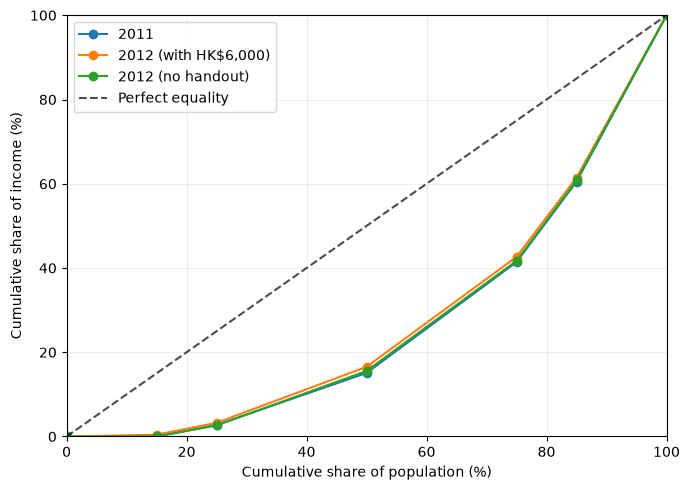

In [105]:
if USE_LETS_PLOT:
    display(
        ggplot(
            long_incomes_shares, # dataset
        
            aes(
                x="Percentile",                     # x-axis is percentile
                y="Cumulative share of income (%)", # y-axis is cumulative share
                color="Year"                        # separated by year (color)
                ),

        )

        # geom_abline is for drawing reference lines
        + geom_abline(
            slope=1,       # slope is 1 (45 degree line)
            color="black",
            linetype=2,    # 2 - dashed line
            alpha=0.7      # 70% opaque
            )

        + geom_line(size=1)
        + geom_point(size=3)
        + labs(x="Cumulative share of the population (%)")
    )
else:
    fig, ax = plt.subplots(figsize=(7,5))
    for name, group in long_incomes_shares.groupby("Year", sort=False):
        ax.plot(group["Percentile"], group["Cumulative share of income (%)"], marker="o", label=name)
    ax.plot([0,100],[0,100],"k--",label="Perfect equality",alpha=.7)
    ax.set(xlabel="Cumulative share of population (%)", ylabel="Cumulative share of income (%)", xlim=(0,100), ylim=(0,100))
    ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show()

**Interpretation:** The 2012 curve with the transfer lies closer to the equality line than the 2011 curve. The bottom half's share rises from about 15.09% to 16.54%. The 2012 no-transfer curve isolates the payment effect at fixed 2012 incomes. The zero-income assumption and group weights are modelling choices, not observed household microdata.

### Question 3 — Gini coefficients (2011–2013)

In [106]:
years_of_interest = [2011, 2012, 2013]

                  # monthly income in years 2011-2013, sorted from lowest to highest
raw_percentiles = income.loc[:, years_of_interest].sort_values(2011)
                                                 #.sort_values(2011) - uses the 2011 column to sort the values (low to high)

raw_percentiles = raw_percentiles * 12

raw_percentiles = pd.concat(
    [
        pd.DataFrame( # adding a row of 0s again (for percentiles)
            [[0, 0, 0]],
            columns=years_of_interest,
            index=[6],
        ),
        raw_percentiles,
    ],
).reset_index(drop=True) # resets row labels

In [107]:
#Annual household income before transfers (HKD)
raw_percentiles.round(2)

,2011,2012,2013
0,0.00,0.00,0.00
1,55644.59,53453.01,52274.28
2,100160.26,105836.97,102498.59
3,213675.21,213812.05,223446.92
4,387286.32,390207.00,409994.35
5,534188.03,534530.13,543242.51


In [108]:
households=[15, 10, 25, 25, 10, 15] # list of numbers of households in each group

hh_percentiles = pd.DataFrame()     # creating an empty dataframe

for year in raw_percentiles.columns:
    
    hh_percentiles_by_year = pd.DataFrame()
    
    for i, num_hhds in enumerate(households):
        num_income = raw_percentiles.loc[i, year]
        hh_percentiles_by_year = pd.concat(
            [hh_percentiles_by_year, pd.DataFrame(np.repeat(num_income, num_hhds))],
            axis=0,
        )
        hh_percentiles_by_year["year"] = year

    hh_percentiles_by_year = hh_percentiles_by_year.reset_index(drop=True)
    hh_percentiles_by_year["percentile"] = hh_percentiles_by_year.index % 100 + 1
    
    if year == 2012:
        hh_percentiles_by_year[0] = hh_percentiles_by_year[0] + 6000

    hh_percentiles = pd.concat([hh_percentiles, hh_percentiles_by_year], axis=0)

In [109]:
hh_percentiles.tail()

,0,year,percentile
95,543242.513405,2013,96
96,543242.513405,2013,97
97,543242.513405,2013,98
98,543242.513405,2013,99
99,543242.513405,2013,100


#### Gini coefficient
The Gini coefficient is half the *relative mean absolute difference*: compare every household's income with every other household's, average the absolute gaps, and divide by mean income. 0 = perfect equality; with 100 equally weighted households the theoretical maximum is 0.99 (one household receives all income).

In [110]:
def gini_coefficient(x):
    x = np.double(x.values)                         # incomes as decimals
    x = x / x.sum()                                 # normalise (doesn't change the Gini)
    mad = np.abs(np.subtract.outer(x, x)).mean()    # mean absolute difference between every pair of households
    rmad = mad / np.mean(x)                         # relative to the mean
    g = 0.5 * rmad                                  # Gini = half the relative mean absolute difference
    return g

In [111]:
# one column per year, one row per household (100 rows)
hh_wide = hh_percentiles.pivot(index="percentile", columns="year", values=0)

# 2012 WITHOUT the handout, to isolate the handout's own effect
hh_wide["2012 (no handout)"] = hh_wide[2012] - 6000

gini = hh_wide.apply(lambda x: gini_coefficient(x), axis=0)
gini = gini.rename(index={2011: "2011", 2012: "2012 (with HK$6,000)", 2013: "2013"})
gini = gini.reindex(["2011", "2012 (no handout)", "2012 (with HK$6,000)", "2013"])
gini.round(4)

year
2011                    0.4688
2012 (no handout)       0.4652
2012 (with HK$6,000)    0.4519
2013                    0.4698
dtype: float64

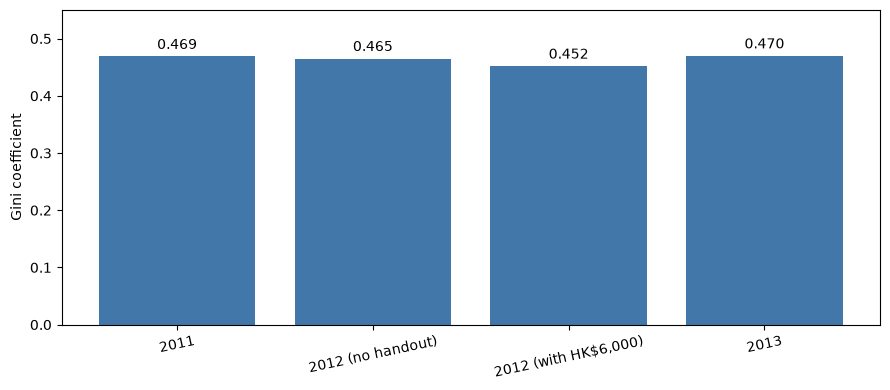

In [112]:
if USE_LETS_PLOT:
    gini_df = gini.reset_index()
    gini_df.columns = ["Scenario", "Gini"]
    display(
        ggplot(gini_df, aes(x="Scenario", y="Gini", fill="Scenario"))
        + geom_bar(stat="identity", width=0.6, show_legend=False)
        + geom_text(aes(label="Gini"), label_format=".3f", nudge_y=0.002, size=7)
        + coord_cartesian(ylim=[0, 0.55])
        + labs(x="", y="Gini coefficient")
    )
else:
    gini_df = gini.reset_index()
    gini_df.columns = ["Scenario", "Gini"]
    fig, ax = plt.subplots(figsize=(9,4))
    bars = ax.bar(gini_df["Scenario"], gini_df["Gini"], color="#4177a9")
    ax.bar_label(bars, fmt="%.3f", padding=3); ax.set(ylabel="Gini coefficient", ylim=(0,.55))
    ax.tick_params(axis="x", rotation=12); fig.tight_layout(); plt.show()

**Interpretation:** The modelled Gini is lower in 2012 with the transfer than in 2011, and returns above its 2011 value in 2013. Comparing 2012 with and without the payment holds baseline incomes fixed and isolates the transfer's mechanical effect within the model. It is not an estimate of an observed economy-wide causal effect. The transfer raises relative incomes more at the bottom; the subsequent rebound reflects both the removal of the payment and changes in pre-transfer incomes. The comparison cannot establish what actual long-run inequality would have been without the scheme.

### Question 4 — Counterfactual policy simulations
Same budget as the handout in our 100-household model: 100 x HK$6,000 = HK$600,000.
* **Targeted transfer:** give the whole budget to the 15 zero-income households (HK$40,000 each).
* **Progressive tax:** 10% tax on the top 25 households' 2012 income, shared equally by the bottom 25 households.

These are illustrative model scenarios rather than observed historical policies. The tax scenario redistributes tax revenue (not the same external budget as the two cash-transfer scenarios).

In [113]:
base_2012 = hh_wide["2012 (no handout)"].sort_values().reset_index(drop=True)  # 100 households, low -> high
budget = 100 * 6000

scenarios = pd.DataFrame({"No policy": base_2012})
scenarios["Universal HK$6,000"] = base_2012 + 6000

targeted = base_2012.copy()
targeted.iloc[:15] += budget / 15          # bottom 15 households share the whole budget
scenarios["Targeted to bottom 15%"] = targeted

taxed = base_2012.copy()
revenue = 0.10 * taxed.iloc[75:].sum()     # 10% tax on the top 25 households
taxed.iloc[75:] *= 0.90
taxed.iloc[:25] += revenue / 25            # shared by the bottom 25 households
scenarios["10% tax on top 25%"] = taxed

cf_gini = scenarios.apply(gini_coefficient).round(4)
cf_gini

No policy                 0.4652
Universal HK$6,000        0.4519
Targeted to bottom 15%    0.4277
10% tax on top 25%        0.3767
dtype: float64

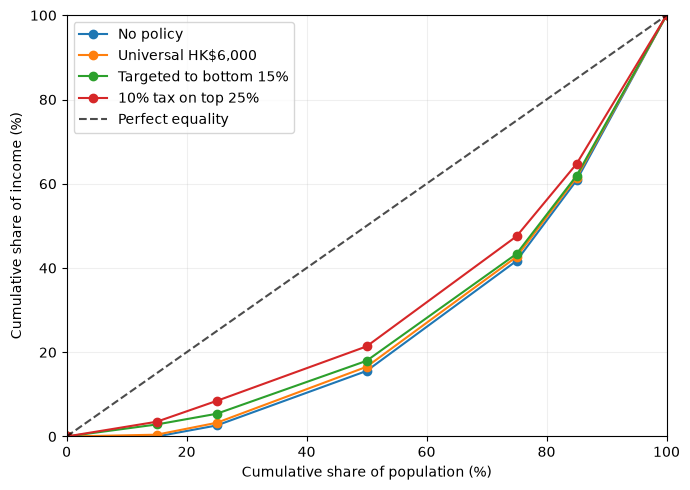

In [114]:
cuts = [0, 15, 25, 50, 75, 85, 100]
cf_lorenz = pd.DataFrame({"Percentile": cuts})
for name in scenarios.columns:
    s = scenarios[name].sort_values().reset_index(drop=True)
    cum = 100 * s.cumsum() / s.sum()
    cf_lorenz[name] = [0] + [cum.iloc[c - 1] for c in cuts[1:]]
cf_long = pd.melt(cf_lorenz, id_vars="Percentile", var_name="Scenario", value_name="Cumulative share of income (%)")
if USE_LETS_PLOT:
    display(
        ggplot(cf_long, aes(x="Percentile", y="Cumulative share of income (%)", color="Scenario"))
        + geom_abline(slope=1, color="black", linetype=2, alpha=0.7)
        + geom_line(size=1) + geom_point(size=3)
        + labs(x="Cumulative share of the population (%)")
    )
else:
    fig, ax = plt.subplots(figsize=(7,5))
    for name, group in cf_long.groupby("Scenario", sort=False):
        ax.plot(group["Percentile"], group["Cumulative share of income (%)"], marker="o", label=name)
    ax.plot([0,100],[0,100],"k--", label="Perfect equality", alpha=.7)
    ax.set(xlabel="Cumulative share of population (%)", ylabel="Cumulative share of income (%)", xlim=(0,100), ylim=(0,100))
    ax.grid(alpha=.2); ax.legend(); fig.tight_layout(); plt.show()

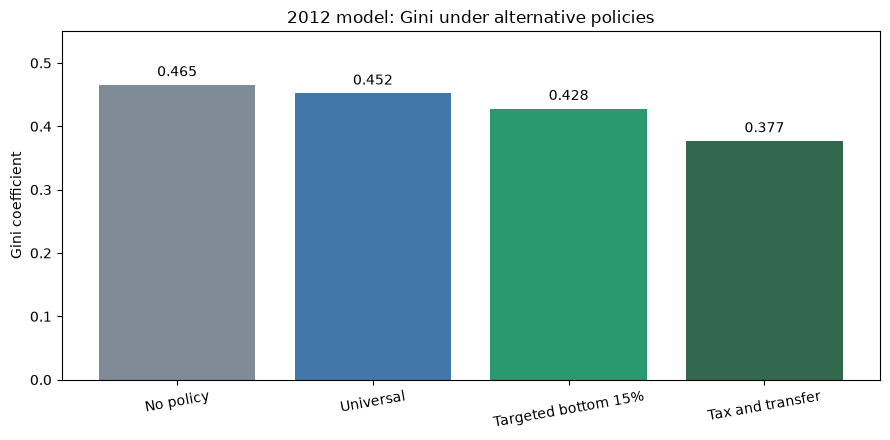

Tax revenue redistributed (HKD): 1,192,002


In [115]:
# Compare the four scenarios using the same Gini measure (Slide 12).
fig, ax = plt.subplots(figsize=(9, 4.5))
labels = ["No policy", "Universal", "Targeted bottom 15%", "Tax and transfer"]
bars = ax.bar(labels, cf_gini.values, color=["#7f8b97", "#4177a9", "#2b9970", "#32684c"])
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set(ylabel="Gini coefficient", title="2012 model: Gini under alternative policies", ylim=(0, 0.55))
ax.tick_params(axis="x", labelrotation=10)
fig.tight_layout(); plt.show()
print(f"Tax revenue redistributed (HKD): {revenue:,.0f}")

**Interpretation (CORE 12.1 Q4):** Additional transfers to households at or below the 15th percentile would raise their cumulative income shares and tend to move the Lorenz curve toward the equality line. Taxing households at or above the 75th percentile would reduce their relative disposable income; redistribution of the revenue to poorer households would tend to reduce inequality further. In the model, the targeted transfer lowers Gini more than the equal-budget universal transfer, and the tax-and-transfer scenario lowers it further. The tax scenario has a larger redistribution volume, so it is not an equal-budget comparison. Income rankings are recalculated after each intervention.

<!-- HARUT_PART4_BEGIN -->
## CORE Part 12.2 — Government popularity and public opinion

**Research question:** Was Hong Kong's Scheme $6,000 followed by a sustained improvement in satisfaction with the HKSAR Government?

This section follows CORE Econ, *Doing Economics*, Project 12, **Part 12.2 (Working in Python)**, Questions 1–5 and Python walk-throughs 12.5–12.6. It uses survey **end dates**, the original net-satisfaction definition, and two related social indicators: *degree of prosperity* and *degree of equality*.

**Data files (HKU POP / PORI):**
- `People’s Satisfaction with the HKSAR Government.xlsx`
- `Appraisal of Degree of Prosperity.xlsx`
- `Appraisal of Degree of Equality.xlsx`

For a reproducible final group submission, put all three Excel files under `data/` in this repository. During development, this section also searches a sibling checkout of the original `Macroeconomics-hong-kong-cash-handout/data` folder.

CORE instructions: https://books.core-econ.org/doing-economics/book/text/12-06.html#part-122-government-popularity

PORI historical indicator archive: https://a2024.pori.hk/pop-poll/social-indicators.html?lang=en


### Question 1 — Who might favour or oppose a universal HK$6,000 handout?

**Possible supporters:** adult permanent residents seeking immediate relief from higher living costs; people not covered by the original MPF-based proposal; and the government, if the scheme made surplus redistribution more publicly acceptable.

**Possible opponents:** people favouring long-term public services, anti-poverty measures or housing assistance over a one-off payment; advocates of means-testing who object to paying high-income residents the same amount; and groups excluded by the permanent-resident eligibility rule.

These are plausible incentives, **not survey estimates of support by demographic group**. The policy was a broad cash transfer rather than an income-tested poverty programme.

Policy background: https://www.news.gov.hk/en/categories/health/html/2011/06/20110616_143944.shtml


### Question 2 — Survey methodology and representativeness

The historical HKU Public Opinion Programme used **random telephone surveys conducted by interviewers** and weighted results to population characteristics such as age and sex. Telephone surveys are useful for repeated trend measurements, but do not automatically provide a perfectly representative sample. The survey's *base/number of raters* can be smaller than its overall sample, and response rates do not eliminate nonresponse bias.

Potential limitations:

- Household telephone access and willingness to answer may be related to respondent characteristics.
- Question-specific subsamples yield fewer observations than the survey's headline sample.
- Government satisfaction reflects many political and economic issues, not just Scheme $6,000.
- Historical survey practices changed over time: mobile-phone samples were introduced into HKU POP's regular tracking frame from 2017, which matters when comparing the full 2006–2024 series.
- These are **repeated cross-sectional surveys**, not a randomized evaluation of a policy.

Survey methods and historical details: https://hkupop.pori.hk/english/features/budget/surveymethod.html and https://hkupop.pori.hk/english/release/release1497.html


In [116]:
# Part 12.2 — imports and source-file discovery (all variables prefixed p4_)
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

p4_files = {
    "satisfaction": "People’s Satisfaction with the HKSAR Government.xlsx",
    "prosperity": "Appraisal of Degree of Prosperity.xlsx",
    "equality": "Appraisal of Degree of Equality.xlsx",
}

# We can run from the repo root or notebooks/; the old repo may be a sibling folder.
p4_cwd = Path.cwd()
p4_search_dirs = []
for p4_parent in [p4_cwd, p4_cwd.parent, p4_cwd.parent.parent]:
    p4_search_dirs.extend([
        p4_parent / "data",
        p4_parent / "Macroeconomics-hong-kong-cash-handout" / "data",
    ])
p4_data_dir = next(
    (d for d in p4_search_dirs if all((d / name).is_file() for name in p4_files.values())),
    None,
)
if p4_data_dir is None:
    raise FileNotFoundError(
        "Part 4 needs three HKU POP Excel files in macro_final/data/. "
        "Copy them from the earlier Macroeconomics-hong-kong-cash-handout/data folder "
        "and rerun this cell. Required: " + ", ".join(p4_files.values())
    )
print("Part 4 data folder:", p4_data_dir.resolve())


Part 4 data folder: C:\Users\PrestamoTGC\macro_final\data


In [117]:
# CORE walk-through 12.5: header is row 2, so use skiprows=1.
def p4_load_survey(filename, value_columns, respondents_column):
    raw = pd.read_excel(p4_data_dir / filename, skiprows=1)
    rename = {
        "調查開始日期Survey Start Date": "start_date",
        "調查結束日期Survey End Date": "survey_date",
        "樣本數目Sample size": "sample_size",
        "回應比率Response rate": "response_rate",
        "回應比率Response Rate": "response_rate",
        respondents_column: "respondents",
        **value_columns,
    }
    data = raw.rename(columns=rename).copy()
    required = ["survey_date", "sample_size", "response_rate", "respondents", *value_columns.values()]
    absent = [c for c in required if c not in data.columns]
    if absent:
        raise ValueError(f"Unexpected column layout in {filename}: {absent}")
    data["survey_date"] = pd.to_datetime(data["survey_date"], errors="coerce")
    if "start_date" in data.columns:
        data["start_date"] = pd.to_datetime(data["start_date"], errors="coerce")
    for col in required:
        if col != "survey_date":
            data[col] = pd.to_numeric(data[col], errors="coerce")
    # Keep valid survey observations; do not drop rows just because the Remark field is empty.
    data = data.dropna(subset=["survey_date", *value_columns.values()])
    data = data.sort_values("survey_date").reset_index(drop=True)
    return data

p4_satisfaction = p4_load_survey(
    p4_files["satisfaction"],
    {"滿意Satisfied": "satisfied", "唔滿意Dissatisfied": "dissatisfied",
     "淨值Netvalue": "reported_net", "平均量值Mean value": "mean_satisfaction"},
    "基數Base",
)
p4_prosperity = p4_load_survey(
    p4_files["prosperity"], {"繁榮Prosperity": "prosperity"},
    "評分人數Number of Raters",
)
p4_equality = p4_load_survey(
    p4_files["equality"], {"平等Equality": "equality"},
    "評分人數Number of Raters",
)

for p4_name, p4_df in [("Government satisfaction", p4_satisfaction),
                       ("Prosperity", p4_prosperity), ("Equality", p4_equality)]:
    print(f"{p4_name}: {len(p4_df)} observations; "
          f"{p4_df.survey_date.min().date()} through {p4_df.survey_date.max().date()}")


Government satisfaction: 406 observations; 1997-07-30 through 2024-11-07
Prosperity: 105 observations; 1997-06-25 through 2024-09-04
Equality: 79 observations; 1997-06-25 through 2024-09-04


In [118]:
# Survey reliability summary for the relevant 2009–2013 period.
p4_survey_summary = []
for p4_name, p4_df in [("Net government satisfaction", p4_satisfaction),
                       ("Degree of prosperity", p4_prosperity),
                       ("Degree of equality", p4_equality)]:
    p4_window = p4_df.loc[p4_df.survey_date.dt.year.between(2009, 2013)]
    p4_survey_summary.append({
        "Indicator": p4_name,
        "Surveys (2009–13)": len(p4_window),
        "Mean full sample": p4_window.sample_size.mean(),
        "Mean question respondents": p4_window.respondents.mean(),
        "Mean response rate (%)": p4_window.response_rate.mean() * 100,
    })
p4_survey_summary = pd.DataFrame(p4_survey_summary)
display(p4_survey_summary.round(1))


,Indicator,Surveys (2009–13),Mean full sample,Mean question respondents,Mean response rate (%)
0,Net government satisfaction,79,1014.8,726.3,67.2
1,Degree of prosperity,10,1022.1,752.8,66.1
2,Degree of equality,10,1022.1,658.5,66.1


### Question 3 — Net government satisfaction, prosperity and equality (2006–2024)
Calculate net satisfaction from the shares satisfied and dissatisfied, cross-check it against the published value, and plot the three indicators using survey end dates.

Maximum difference vs published net value: 0.1 pp


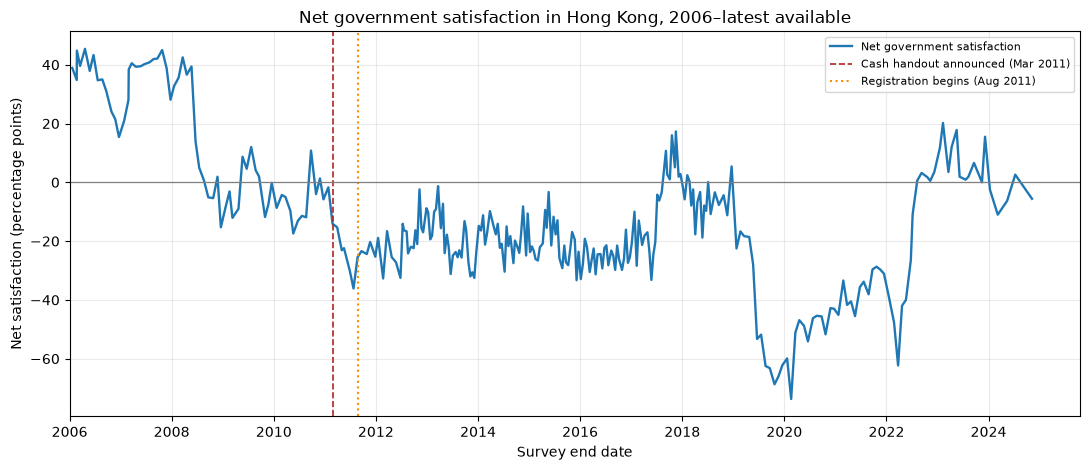

297 observations; latest survey: 2024-11-07


In [119]:
# CORE 12.6: calculate net satisfaction as a percentage-point difference.
p4_satisfaction["net_pp"] = 100 * (
    p4_satisfaction["satisfied"] - p4_satisfaction["dissatisfied"]
)
p4_satisfaction["reported_net_pp"] = 100 * p4_satisfaction["reported_net"]
p4_error = (p4_satisfaction["net_pp"] - p4_satisfaction["reported_net_pp"]).abs()
print("Maximum difference vs published net value:", round(p4_error.max(), 3), "pp")
assert p4_error.max() <= 0.11, "Net satisfaction disagrees with the source data."

p4_survey_data = {
    "Net government satisfaction": (p4_satisfaction, "net_pp", "Percentage points"),
    "Degree of prosperity": (p4_prosperity, "prosperity", "Appraisal (0–10)"),
    "Degree of equality": (p4_equality, "equality", "Appraisal (0–10)"),
}

p4_policy_announcement = pd.Timestamp("2011-03-02")
p4_registration_begins = pd.Timestamp("2011-08-28")

def p4_plot_series(title, df, value_col, y_label):
    series = df.loc[df["survey_date"] >= "2006-01-01"].dropna(subset=[value_col])
    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.plot(series["survey_date"], series[value_col], linewidth=1.7, label=title)
    ax.axvline(p4_policy_announcement, linestyle="--", color="firebrick",
               linewidth=1.2, label="Cash handout announced (Mar 2011)")
    ax.axvline(p4_registration_begins, linestyle=":", color="darkorange",
               linewidth=1.5, label="Registration begins (Aug 2011)")
    if value_col == "net_pp":
        ax.axhline(0, linewidth=0.9, color="gray")
    else:
        ax.set_ylim(0, 10)
    ax.set_xlim(left=pd.Timestamp("2006-01-01"))
    ax.set_title(title + " in Hong Kong, 2006–latest available")
    ax.set_xlabel("Survey end date")
    ax.set_ylabel(y_label)
    ax.grid(alpha=0.25)
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    plt.show()
    print(f"{len(series)} observations; latest survey: {series.survey_date.max().date()}")

# CORE Question 3(a): net satisfaction, Jan 2006 through latest available.
p4_plot_series("Net government satisfaction", p4_satisfaction, "net_pp", "Net satisfaction (percentage points)")


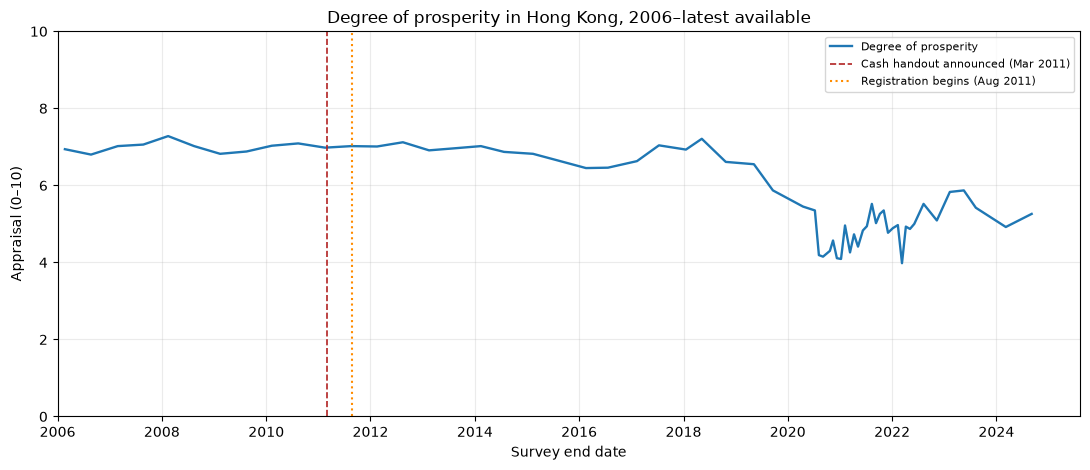

61 observations; latest survey: 2024-09-04


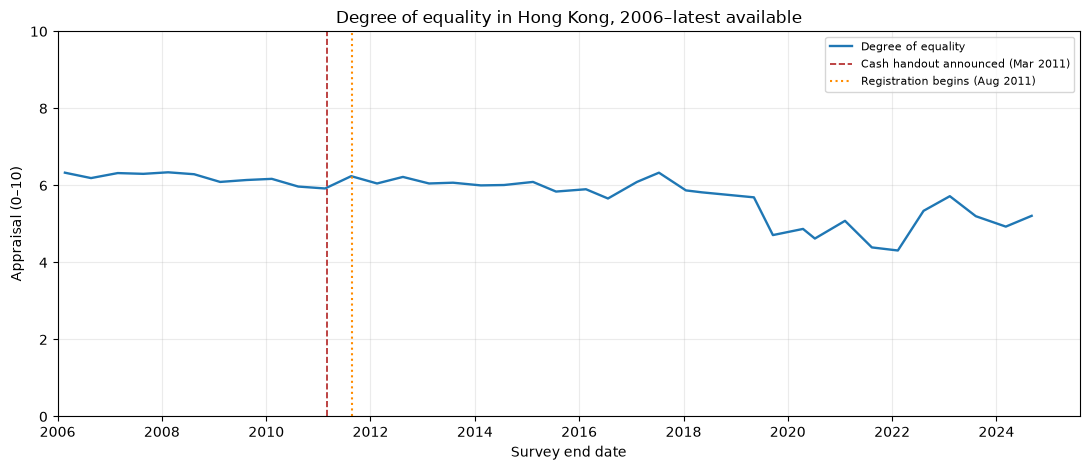

38 observations; latest survey: 2024-09-04


In [120]:
# CORE Question 3(b)–(c): one or two related indicators, separate charts.
p4_plot_series("Degree of prosperity", p4_prosperity, "prosperity", "Appraisal (0–10)")
p4_plot_series("Degree of equality", p4_equality, "equality", "Appraisal (0–10)")


#### Interpreting the charts and comparing the periods

The three charts deliberately use the **same date window** (January 2006 to each indicator's latest available survey), but government satisfaction is in **percentage points** whereas prosperity and equality are appraisals on a **0–10 scale**. We compare *directions and persistence of changes*, not the levels of the three different scales.

The vertical lines identify the March 2011 policy announcement and August 2011 start of registration. They **do not establish a causal break**. Also, the CORE 2012 Gini simulation is a hypothetical accounting exercise; it should not be confused with the actual timing of registrations and disbursements.

For clarity, the next cell compares two pre-policy years (2009–2010) with two later years (2012–2013), using *equal weight per year's mean* rather than allowing months with more polls to dominate.


In [121]:
# Descriptive before-and-after comparison; 2011 excluded as a transition year.
p4_comparisons = []
for p4_name, (p4_df, p4_col, p4_units) in p4_survey_data.items():
    p4_annual = p4_df.assign(year=p4_df.survey_date.dt.year).groupby("year")[p4_col].mean()
    p4_before = p4_annual.reindex([2009, 2010]).mean()
    p4_after = p4_annual.reindex([2012, 2013]).mean()
    p4_comparisons.append({
        "Indicator": p4_name,
        "2009–2010 mean": p4_before,
        "2012–2013 mean": p4_after,
        "Difference": p4_after - p4_before,
        "Units": p4_units,
    })
p4_comparison = pd.DataFrame(p4_comparisons)
display(p4_comparison.round(3))
print("These are descriptive changes, not estimates of the handout's causal effect.")


,Indicator,2009–2010 mean,2012–2013 mean,Difference,Units
0,Net government satisfaction,-4.162,-19.536,-15.374,Percentage points
1,Degree of prosperity,6.955,7.000,0.045,Appraisal (0–10)
2,Degree of equality,6.092,6.098,0.005,Appraisal (0–10)


These are descriptive changes, not estimates of the handout's causal effect.


#### Linking perceived equality to the Part 12.1 model

Our implementation of CORE's **hypothetical 100-household model** calculates Gini coefficients of approximately **0.468760 (2011), 0.451902 (2012 with the assumed HK$6,000 transfer), and 0.469819 (2013)**. These are not observed official Hong Kong Gini statistics; they result from the exercise's assumptions. Compare them with mean survey perceptions, not as if they measured the same thing.

The model treats the handout as an addition to 2012 incomes for instructional purposes. The actual registration programme began in August **2011**, with eligibility/registration arrangements extending into **2012**.

CORE model: https://books.core-econ.org/doing-economics/book/text/12-06.html#part-121-inequality
Official registration announcement: https://www.news.gov.hk/en/categories/health/html/2011/06/20110616_143944.shtml


In [122]:
p4_core_gini = pd.DataFrame({
    "year": [2011, 2012, 2013],
    "CORE modelled Gini": [gini.loc["2011"], gini.loc["2012 (with HK$6,000)"], gini.loc["2013"]],
})
p4_equality_annual = (
    p4_equality.assign(year=p4_equality.survey_date.dt.year)
    .loc[lambda d: d.year.between(2011, 2013)]
    .groupby("year").agg(
        perceived_equality=("equality", "mean"),
        survey_count=("equality", "size")
    ).reset_index()
)
p4_gini_perception = p4_core_gini.merge(p4_equality_annual, on="year", how="left")
display(p4_gini_perception.round(4))


,year,CORE modelled Gini,perceived_equality,survey_count
0,2011,0.4688,6.080,2
1,2012,0.4519,6.135,2
2,2013,0.4698,6.060,2


#### Findings, alternative explanations, and limitations

**Interpretation:** The before/after table and three time-series plots should be read together. In the computed comparison, net government satisfaction fell rather than showing a sustained post-handout increase, while prosperity and equality perceptions changed much less.

This means **we cannot claim that Scheme $6,000 produced a lasting popularity gain**. However, it also does **not prove that the scheme caused dissatisfaction**: we have neither a matched control group nor a counterfactual popularity trend. Inflation, housing costs, wider economic conditions, political disputes around the Budget, and changes in political leadership may have contributed to the movements.

**Connection with inequality:** CORE's simplified model shows a lower Gini in its transfer year followed by a reversal in 2013. The accompanying equality appraisals move only slightly, illustrating the distinction between a mechanical redistribution simulation and how society perceives equality.

**Sampling caveats:** The full sample is not the same as the number answering each question. Survey participation, coverage, weighting, and changes in the telephone sampling frame can affect trend comparisons. Don't interpret the 0–10 appraisal scores as percentages.

### Question 4 — Comparing the 2011 and 2018 cash handouts

The **2011 Scheme $6,000** provided the same payment to eligible permanent residents aged 18 or over. The payment represented a larger share of a poorer household's income, but the broad eligibility also included wealthy residents. Its relatively simple eligibility rules reduced administrative complexity.

The **2018 Caring and Sharing Scheme**, announced on 23 March 2018, offered eligible adults up to HK$4,000, or the difference after applicable tax and rates concessions. It aimed to extend relief to residents who received little from other budget measures; it was not a simple income-tested poverty programme. Applications opened on 1 February 2019. The original estimate was about 2.8 million eligible people and HK$11 billion in payments. By October 2019, the government reported that HK$10.6 billion in payments had been approved for 2.99 million applications.

The article recommended by CORE reported estimated administration costs of HK$330 million (about 2.9% of the 2018 programme, compared with 0.5% of the 2011 programme). This illustrates the trade-off between more selective eligibility and administrative complexity. We prefer the more targeted design when the objective is reducing inequality, but the evidence here does not measure its actual causal effectiveness or show that every eligible person received support.

Sources: [CORE Project 12, Part 12.2](https://books.core-econ.org/doing-economics/book/text/12-06.html#part-122-government-popularity); [Government announcement, 23 March 2018](https://www.info.gov.hk/gia/general/201803/23/P2018032300887.htm); [Application dates and rules](https://www.info.gov.hk/gia/general/201812/31/P2018123100468.htm); [SCMP article specified by CORE](https://www.scmp.com/news/hong-kong/politics/article/2142707/hong-kong-cash-handout-scheme-will-cost-government-hk330).

Additional sources: [Initial cost and eligibility estimate](https://www.info.gov.hk/gia/general/201803/23/P2018032300710.htm); [Implementation update, 2 October 2019](https://www.info.gov.hk/gia/general/201910/02/P2019100200609p.htm).

### Question 5 — Policy recommendation and overall conclusion

For a developed economy with a budget surplus and an objective of reducing income inequality, we recommend **targeted and recurring support for lower-income households**, provided that ongoing funding is sustainable. In our model, the same HK$600,000 budget reduces the 2012 Gini from approximately 0.465 to 0.428 when concentrated on the poorest 15 households, versus 0.452 under the universal payment. The separate tax-and-transfer scenario illustrates how progressive taxation could further reduce inequality, but redistributes a different amount and is not a like-for-like budget comparison.

A revised 2018-style design could use existing tax and social-security systems, simplify applications, reduce exclusion errors, and deliver assistance regularly rather than as a one-off. A one-time budget surplus alone cannot guarantee recurring financing. Longer-term housing, education, employment and social-protection measures should complement cash support. Universal transfers may still be preferable where speed and simple coverage are the primary objectives.

**Conclusion:** Our hypothetical model shows a temporary reduction in inequality in the transfer year, while the observed opinion surveys show no sustained improvement in government satisfaction after the 2011 scheme. The model assumes six income groups, a payment per hypothetical household, no behavioural responses and no other interventions; the public opinion comparison lacks a credible causal counterfactual. Consequently, these results inform policy design rather than establish the actual causal effect of either scheme.

## Appendix — Optional CORE inflation extension: consumer prices (CPI)
The datafile also gives the year-on-year % change in consumer prices. We build an inflation index (2009 = 1), as in CORE's extension, and check that real income = nominal income / index.

In [123]:
raw_file = pd.read_excel(Path("data/doing-economics-project-12-datafile.xlsx"), header=None)
cpi = pd.DataFrame({
    "Year": list(range(2009, 2017)),
    "CPI change (%)": raw_file.iloc[9, 1:9].astype(float).values,   # row 10 of the sheet
})
cpi.loc[0, "CPI change (%)"] = 0                                     # 2009 is the base year
cpi["Inflation index"] = (1 + cpi["CPI change (%)"] / 100).cumprod() # 2009 = 1

nominal = pd.read_excel(Path("data/doing-economics-project-12-datafile.xlsx"), skiprows=2, nrows=5)
nominal = nominal.rename(columns={"Percentile": "Percentile"}).set_index("Percentile")
check = nominal[list(range(2009, 2017))] / cpi["Inflation index"].values
print("Largest gap vs published real income (HKD):",
      round((check.values - income.set_index("Percentile")[list(range(2009, 2017))].values).__abs__().max(), 1))
cpi.round(3)

Largest gap vs published real income (HKD): 0.0


,Year,CPI change (%),Inflation index
0,2009,0.0,1.000
1,2010,2.4,1.024
2,2011,5.3,1.078
3,2012,4.1,1.122
4,2013,4.3,1.171
5,2014,4.4,1.222
6,2015,3.0,1.259
7,2016,2.4,1.289


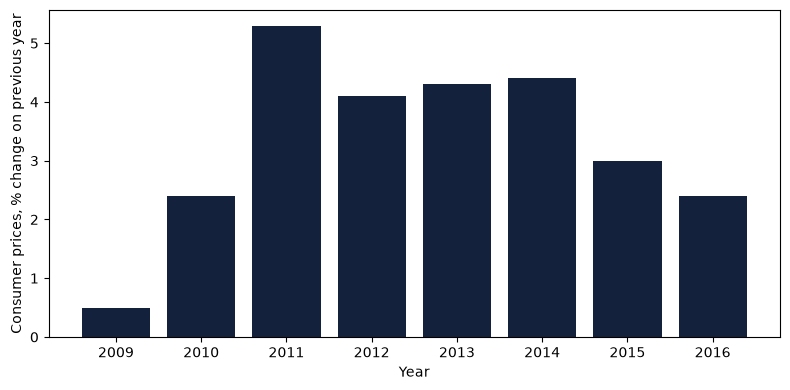

In [124]:
if USE_LETS_PLOT:
    display(
        ggplot(cpi.assign(**{"CPI change (%)": raw_file.iloc[9, 1:9].astype(float).values}),
               aes(x=as_discrete("Year"), y="CPI change (%)"))
        + geom_bar(stat="identity", fill="#14213D", width=0.6)
        + labs(y="Consumer prices, % change on previous year", x="Year")
    )
else:
    fig, ax = plt.subplots(figsize=(8,4))
    ax.bar(cpi["Year"], raw_file.iloc[9, 1:9].astype(float).values, color="#14213D")
    ax.set(xlabel="Year", ylabel="Consumer prices, % change on previous year"); fig.tight_layout(); plt.show()

## Final validation
The following assertions check the main results, complete year coverage, the household counts and consistency of the Lorenz shares and Gini calculations. They are reproducibility checks, not additional CORE questions.

In [125]:
assert set(income_melted["Year"]) == set(range(2009, 2017))
assert len(hh_wide) == 100 and np.allclose(hh_wide[2012] - hh_wide["2012 (no handout)"], 6000)
assert np.allclose(income_shares.iloc[0, 1:].astype(float), 0)
assert np.allclose(income_shares.iloc[-1, 1:].astype(float), 100)
assert np.allclose(gini.loc[["2011", "2012 (with HK$6,000)", "2013"]], [0.468760, 0.451902, 0.469819], atol=1e-6)
assert np.isclose(scenarios["Targeted to bottom 15%"].sum() - base_2012.sum(), budget)
assert np.isclose(scenarios["10% tax on top 25%"].sum(), base_2012.sum())
assert p4_error.max() <= 0.11
assert [len(p4_satisfaction), len(p4_prosperity), len(p4_equality)] == [406, 105, 79]
print("Validation passed: year coverage, household count, Lorenz endpoints, Gini references, scenario budgets and survey data.")
assert np.allclose(cf_gini.to_numpy(), [0.4652, 0.4519, 0.4277, 0.3767], atol=0.0001)
assert np.allclose(p4_comparison["Difference"], [-15.374, 0.045, 0.005], atol=0.001)
print("Cross-check: all four policy scenarios and three public opinion comparisons match the presentation.")

Validation passed: year coverage, household count, Lorenz endpoints, Gini references, scenario budgets and survey data.
Cross-check: all four policy scenarios and three public opinion comparisons match the presentation.


## References
- CORE Econ (Python, Project 12): https://books.core-econ.org/doing-economics/book/text/12-06.html
- PORI social indicators archive: https://a2024.pori.hk/pop-poll/social-indicators.html?lang=en
- HKU POP methods: https://hkupop.pori.hk/english/features/budget/surveymethod.html
- HKU POP changes to mobile sampling (2017): https://hkupop.pori.hk/english/release/release1497.html
- Hong Kong government, cash-handout registration start: https://www.news.gov.hk/en/categories/health/html/2011/06/20110616_143944.shtml
- Kwong (2013), comparative policy study: https://doi.org/10.1177/186810261304200305
- Household income and consumer prices: CORE Project 12 datafile, drawing on the Hong Kong Poverty Situation Report 2016.
- 2018 policy comparison: official government and SCMP sources linked in Question 4 above.